# 02 - Baseline: TF-IDF + Regressão Logística

O baseline é o modelo clássico contra o qual o LLM será comparado. O TF-IDF transforma cada texto em números (peso de cada palavra ou par de palavras) e a regressão logística aprende a separar positivo de negativo. Treino com 80% dos dados, avaliação nos 20% restantes.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from reviews.avaliacao import CLASSES_MATRIZ, metricas
from reviews.baseline import palavras_mais_fortes, treinar_baseline
from reviews.preparo import carregar_dados

sns.set_theme(style="whitegrid")
treino, teste = carregar_dados(salvar_ids=True)  # salva data/ids_teste.csv
print(len(treino), "treino |", len(teste), "teste")
print(teste["rotulo"].value_counts(normalize=True).round(3).to_dict())

29690 treino | 7423 teste
{'positivo': 0.71, 'negativo': 0.29}


In [2]:
modelo = treinar_baseline(treino["texto"], treino["rotulo"])
previsto = modelo.predict(teste["texto"])
m = metricas(teste["rotulo"], previsto)
print(f"Acurácia: {m['acuracia']:.3f}")
print(f"F1 macro: {m['f1_macro']:.3f}")

Acurácia: 0.925
F1 macro: 0.912


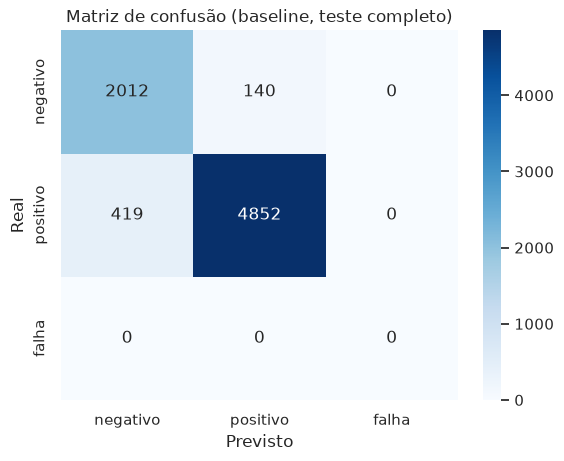

In [3]:
sns.heatmap(m["matriz"], annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES_MATRIZ, yticklabels=CLASSES_MATRIZ)
plt.xlabel("Previsto"); plt.ylabel("Real"); plt.title("Matriz de confusão (baseline, teste completo)")
plt.show()

## Palavras com maiores coeficientes

Em uma regressão logística, coeficiente alto = a palavra empurra a previsão para aquela classe.

In [4]:
fortes = palavras_mais_fortes(modelo, n=15)
for classe, palavras in fortes.items():
    print(f"{classe}: {', '.join(palavras)}\n")

positivo: excelente, recomendo, ótimo, rápida, parabéns, rápido, antes, amei, lindo, muito bom, tudo, adorei, bem, perfeito, obrigada

negativo: não, nao, comprei, não recomendo, nem, péssima, péssimo, diferente, demora, veio, não recebi, aguardando, ruim, quero, quebrado



**Leitura:** os coeficientes fazem sentido: elogios ("excelente", "recomendo", "ótimo", "amei") puxam para positivo e queixas ("não recomendo", "péssimo", "demora", "não recebi", "quebrado") para negativo. "não" e "nao" (sem acento) aparecem separados porque o TF-IDF não normaliza acentos.

## 5 erros do modelo, comentados

In [5]:
erros = teste.assign(previsto=previsto)
erros = erros[erros["rotulo"] != erros["previsto"]].sample(5, random_state=42)
for _, e in erros.iterrows():
    print(f"[real: {e['rotulo']} | previsto: {e['previsto']} | nota {e['nota']}]")
    print(e["texto"], "\n")

[real: negativo | previsto: positivo | nota 2]
foi ruim pq eu tive q buscar no correio o produto e depois vi por mais barato em outros sites. então, pesquisaria mt antes de comprar. 

[real: positivo | previsto: negativo | nota 5]
muita demora na entrega 

[real: positivo | previsto: negativo | nota 4]
estou com problemas na minha entrega e vejo o empenho de todos do stark em resolver esse problema para que eu tenha meu pedido o mais breve possível entregue,empenho nota 1000. 

[real: positivo | previsto: negativo | nota 4]
produto entregue sem defeito e dentro do prazo, mas o produto não é bom; a base é de plástico e muito ruim, as argolas são ruins também. 

[real: negativo | previsto: positivo | nota 1]
excelente 



**Comentários dos 5 erros** (na ordem impressa acima):

1. Crítica irônica/indireta (nota 2): o cliente reclama ("foi ruim", "pesquisaria antes de comprar") mas em tom suave e sem palavras fortemente negativas. O modelo só vê palavras como "antes" e "comprar", que são típicas de positivos.
2. "muita demora na entrega" com nota 5: o texto é negativo, mas o cliente deu nota máxima. Isto é **ruído do rótulo** (nota e texto discordam), não erro do modelo de fato.
3. Nota 4 com texto sobre problema na entrega, mas elogiando o empenho da empresa. Sentimento misto: o baseline pegou "problemas" e "entrega" e previu negativo.
4. Nota 4, mas o texto diz que "o produto não é bom" e que as argolas são ruins. De novo rótulo derivado da nota discordando do texto; o modelo acertou o sentimento do texto e errou o rótulo.
5. "excelente" com nota 1: provavelmente o cliente se enganou na nota. Impossível acertar olhando só o texto.

**Conclusão:** boa parte dos erros vem de rótulos inconsistentes com o texto (2, 4 e 5) e de sentimento misto ou ironia (1 e 3). Isso limita a acurácia máxima possível, para qualquer método, e é uma limitação do projeto (o rótulo vem da nota, não de uma leitura humana do texto).